# Projek Statistika dan Probabilitas
**Analisis Waktu Pengiriman dan Ongkos Kirim pada Data Pesanan E-Commerce Olist sebagai Dasar Perancangan Data Pipeline**

Kelas 3TIC - Kelompok 2 | Konsentrasi: Data Engineer

Dataset: [Brazilian E-Commerce Public Dataset by Olist (Kaggle)](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce)

**Alur notebook:** (1) upload data -> (2) buat dataset -> (3) cek kualitas -> (4) statistika deskriptif (ukuran pemusatan dan penyebaran) -> (5) penyajian data: distribusi frekuensi -> (6) perbandingan antar kelompok ongkos kirim -> (7) simpan hasil

## 1. Persiapan dan Upload Data
Jalankan sel di bawah, lalu pilih 2 file: `olist_orders_dataset.csv` dan `olist_order_items_dataset.csv`.

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display
from google.colab import files

KELAS = "3TIC"
KELOMPOK = "02"
NAMA_DATA = "PesananOlist"

uploaded = files.upload()   # pilih olist_orders_dataset.csv dan olist_order_items_dataset.csv

Saving olist_orders_dataset.csv to olist_orders_dataset.csv


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving olist_order_items_dataset.csv to olist_order_items_dataset.csv


## 2. Membuat Dataset
Kedua file digabung berdasarkan `order_id`, hanya pesanan `delivered` yang dipakai, lalu dihitung `waktu_pengiriman_hari`.

In [ ]:
orders = pd.read_csv("olist_orders_dataset.csv",
    parse_dates=["order_purchase_timestamp", "order_delivered_customer_date"])
items = pd.read_csv("olist_order_items_dataset.csv")

total_awal = len(items)
df = items.merge(orders, on="order_id", how="inner")

# hanya pesanan yang sudah sampai (punya tanggal diterima)
df = df[(df["order_status"] == "delivered") & df["order_delivered_customer_date"].notna()].copy()

# kolom turunan: waktu pengiriman (hari)
df["waktu_pengiriman_hari"] = (
    (df["order_delivered_customer_date"] - df["order_purchase_timestamp"]).dt.total_seconds() / 86400
).round(2)

kolom = ["order_id", "order_item_id", "product_id", "seller_id",
         "order_purchase_timestamp", "order_delivered_customer_date",
         "price", "freight_value", "waktu_pengiriman_hari"]
df = df[kolom].reset_index(drop=True)

print("Baris awal order_items:", total_awal)
print("Baris setelah filter  :", len(df), "| Kolom:", len(df.columns))
df.head()

Baris awal order_items: 112650
Baris setelah filter  : 110189 | Kolom: 9


,order_id,order_item_id,product_id,seller_id,order_purchase_timestamp,order_delivered_customer_date,price,freight_value,waktu_pengiriman_hari
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-13 08:59:02,2017-09-20 23:43:48,58.90,13.29,7.61
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-04-26 10:53:06,2017-05-12 16:04:24,239.90,19.93,16.22
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-14 14:33:31,2018-01-22 13:19:16,199.00,17.87,7.95
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-08 10:00:35,2018-08-14 13:32:39,12.99,12.79,6.15
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-04 13:57:51,2017-03-01 16:42:31,199.90,18.14,25.11


## 3. Pemeriksaan Kualitas Data

In [ ]:
print("Jumlah baris:", len(df))
print("\nData kosong per kolom:")
print(df.isna().sum())
print("\nBaris kembar:", df.duplicated().sum())
print("Kembar order_id + order_item_id:", df.duplicated(["order_id", "order_item_id"]).sum())

VAR = ["price", "freight_value", "waktu_pengiriman_hari"]
NAMA = {"price": "Harga (BRL)", "freight_value": "Ongkos Kirim (BRL)", "waktu_pengiriman_hari": "Waktu Pengiriman (hari)"}
df[VAR].describe()

Jumlah baris: 110189

Data kosong per kolom:
order_id                         0
order_item_id                    0
product_id                       0
seller_id                        0
order_purchase_timestamp         0
order_delivered_customer_date    0
price                            0
freight_value                    0
waktu_pengiriman_hari            0
dtype: int64

Baris kembar: 0
Kembar order_id + order_item_id: 0


,price,freight_value,waktu_pengiriman_hari
count,110189.000000,110189.000000,110189.000000
mean,119.977937,19.948869,12.472224
std,182.304615,15.698615,9.445341
min,0.850000,0.000000,0.530000
25%,39.900000,13.080000,6.740000
50%,74.900000,16.260000,10.180000
75%,134.170000,21.150000,15.540000
max,6735.000000,409.680000,209.630000


## 4. Statistika Deskriptif

In [ ]:
kolom = ["price", "freight_value", "waktu_pengiriman_hari"]
data = df[kolom]

# Kuartil dan batas outlier (metode IQR)
q1 = data.quantile(0.25)
q3 = data.quantile(0.75)
iqr = q3 - q1
batas_bawah = q1 - 1.5 * iqr
batas_atas = q3 + 1.5 * iqr

# Hitung outlier per kolom
outlier = ((data < batas_bawah) | (data > batas_atas)).sum()

# Susun semua metrik jadi satu DataFrame
deskriptif = pd.DataFrame({
    "n": data.count(),
    "Mean": data.mean(),
    "Median": data.median(),
    "Modus": data.mode().iloc[0],
    "Std Dev": data.std(),
    "Min": data.min(),
    "Q1": q1,
    "Q3": q3,
    "Max": data.max(),
    "IQR": iqr,
    "Skewness": data.skew(),
    "Koef. Variasi (%)": data.std() / data.mean() * 100,
    "Jumlah Outlier": outlier,
    "% Outlier": outlier / len(data) * 100,
}).round(3)

deskriptif.index.name = "Variabel"
deskriptif

,n,Mean,Median,Modus,Std Dev,Min,Q1,Q3,Max,IQR,Skewness,Koef. Variasi (%),Jumlah Outlier,% Outlier
Variabel,,,,,,,,,,,,,,
price,110189,119.978,74.90,59.90,182.305,0.85,39.90,134.17,6735.00,94.27,8.031,151.948,8161,7.406
freight_value,110189,19.949,16.26,15.10,15.699,0.00,13.08,21.15,409.68,8.07,5.655,78.694,11811,10.719
waktu_pengiriman_hari,110189,12.472,10.18,7.08,9.445,0.53,6.74,15.54,209.63,8.80,3.840,75.731,5744,5.213


In [ ]:
kolom = {
    'Harga (BRL)': 'price',
    'Ongkos Kirim (BRL)': 'freight_value',
    'Waktu Pengiriman (hari)': 'waktu_pengiriman_hari'
}

hasil = {}

for nama, kol in kolom.items():
    s = df[kol].dropna()

    mean = s.mean()
    median = s.median()
    modus = s.mode().iloc[0]
    selisih = mean - median
    persen = selisih / median * 100

    hasil[nama] = {
        'Mean (rata-rata)': mean,
        'Median': median,
        'Modus': modus,
        'Selisih mean - median': selisih,
        'Selisih terhadap median (%)': persen
    }

tabel = pd.DataFrame(hasil).round(2)
display(tabel)

,Harga (BRL),Ongkos Kirim (BRL),Waktu Pengiriman (hari)
Mean (rata-rata),119.98,19.95,12.47
Median,74.90,16.26,10.18
Modus,59.90,15.10,7.08
Selisih mean - median,45.08,3.69,2.29
Selisih terhadap median (%),60.18,22.69,22.52


In [ ]:
kolom = {
    'Harga (BRL)': 'price',
    'Ongkos Kirim (BRL)': 'freight_value',
    'Waktu Pengiriman (hari)': 'waktu_pengiriman_hari'
}

hasil = {}

for nama, kol in kolom.items():
    s = df[kol].dropna()

    minimum = s.min()
    maksimum = s.max()
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    std = s.std()
    mean = s.mean()
    cv = (std / mean) * 100
    skew = s.skew()

    hasil[nama] = {
        'Minimum': minimum,
        'Maksimum': maksimum,
        'Q1 (kuartil 1)': q1,
        'Q3 (kuartil 3)': q3,
        'IQR (Q3 - Q1)': iqr,
        'Standar deviasi': std,
        'Koefisien variasi (%)': cv,
        'Skewness': skew
    }

tabel = pd.DataFrame(hasil).round(2)
display(tabel)

,Harga (BRL),Ongkos Kirim (BRL),Waktu Pengiriman (hari)
Minimum,0.85,0.00,0.53
Maksimum,6735.00,409.68,209.63
Q1 (kuartil 1),39.90,13.08,6.74
Q3 (kuartil 3),134.17,21.15,15.54
IQR (Q3 - Q1),94.27,8.07,8.80
Standar deviasi,182.30,15.70,9.45
Koefisien variasi (%),151.95,78.69,75.73
Skewness,8.03,5.66,3.84


In [ ]:
kolom = {
    'Harga (BRL)': 'price',
    'Ongkos Kirim (BRL)': 'freight_value',
    'Waktu Pengiriman (hari)': 'waktu_pengiriman_hari'
}

hasil = []

for nama, kol in kolom.items():
    s = df[kol].dropna()

    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1

    batas_bawah = q1 - 1.5 * iqr
    batas_atas = q3 + 1.5 * iqr

    data_bersih = s[
        (s >= batas_bawah) & (s <= batas_atas)
    ]

    mean_awal = s.mean()
    mean_bersih = data_bersih.mean()
    median_awal = s.median()

    penurunan = (
        (mean_awal - mean_bersih) / mean_awal * 100
    )

    hasil.append({
        'Variabel': nama,
        'Jumlah data tanpa outlier': len(data_bersih),
        'Rata-rata semua data': mean_awal,
        'Rata-rata tanpa outlier': mean_bersih,
        'Median semua data': median_awal,
        'Penurunan rata-rata (%)': penurunan
    })

tabel_44 = pd.DataFrame(hasil)
display(tabel_44.round(2))

,Variabel,Jumlah data tanpa outlier,Rata-rata semua data,Rata-rata tanpa outlier,Median semua data,Penurunan rata-rata (%)
0,Harga (BRL),102028,119.98,83.82,74.90,30.14
1,Ongkos Kirim (BRL),98378,19.95,16.12,16.26,19.18
2,Waktu Pengiriman (hari),104445,12.47,10.95,10.18,12.18


In [ ]:
# Fungsi untuk membuat histogram dan boxplot
def plot_deskriptif(v):
    os.makedirs("hasil_analisis", exist_ok=True)   # pastikan folder ada

    fig, ax = plt.subplots(1, 2, figsize=(11, 4))

    # Kiri: histogram
    ax[0].hist(df[v], bins=60, color="#4472C4", edgecolor="white")
    ax[0].set_title(f"Histogram {NAMA[v]}")
    ax[0].set_xlabel(NAMA[v])
    ax[0].set_ylabel("Frekuensi")

    # Kanan: boxplot horizontal
    ax[1].boxplot(df[v], vert=False, showfliers=True,
                  flierprops=dict(markersize=2, alpha=.3))
    ax[1].set_title(f"Boxplot {NAMA[v]}")
    ax[1].set_xlabel(NAMA[v])
    ax[1].set_yticks([])

    plt.tight_layout()
    os.makedirs("hasil_analisis", exist_ok=True)
    plt.savefig(f"hasil_analisis/deskriptif_{v}.png", dpi=150)
    plt.show()

### Gambar 1. Histogram dan boxplot harga

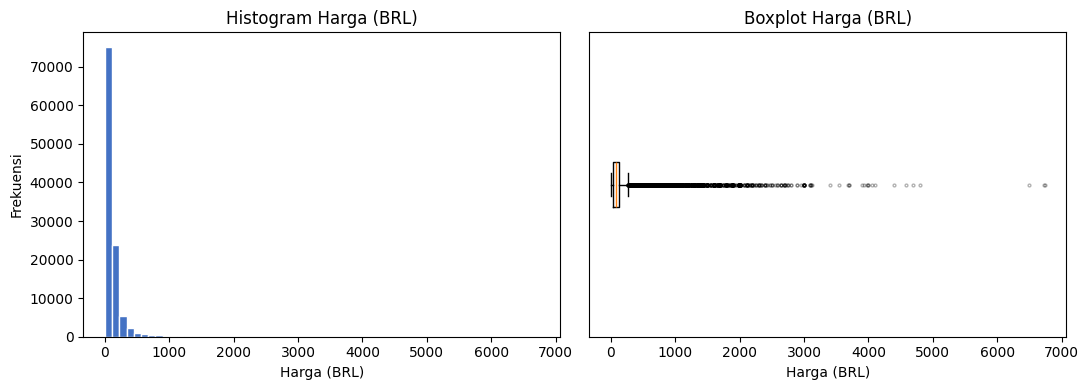

In [ ]:
plot_deskriptif("price")

### Gambar 2. Histogram dan boxplot ongkos kirim

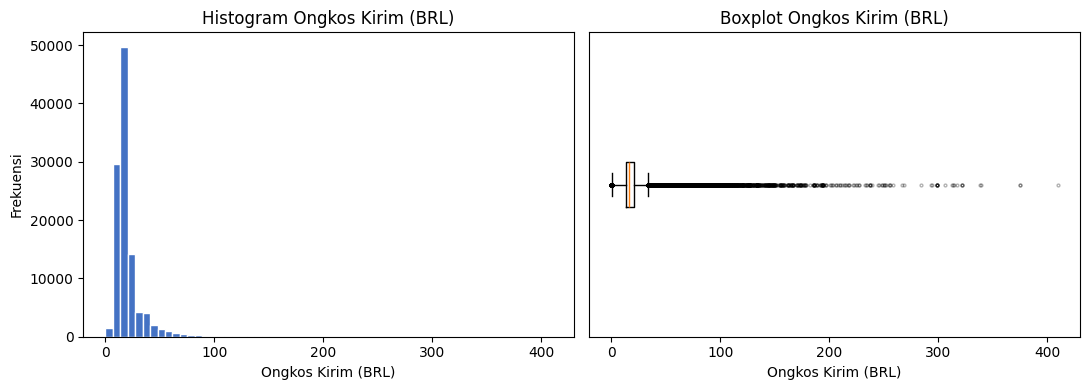

In [ ]:
plot_deskriptif("freight_value")

### Gambar 3. Histogram dan boxplot waktu pengiriman

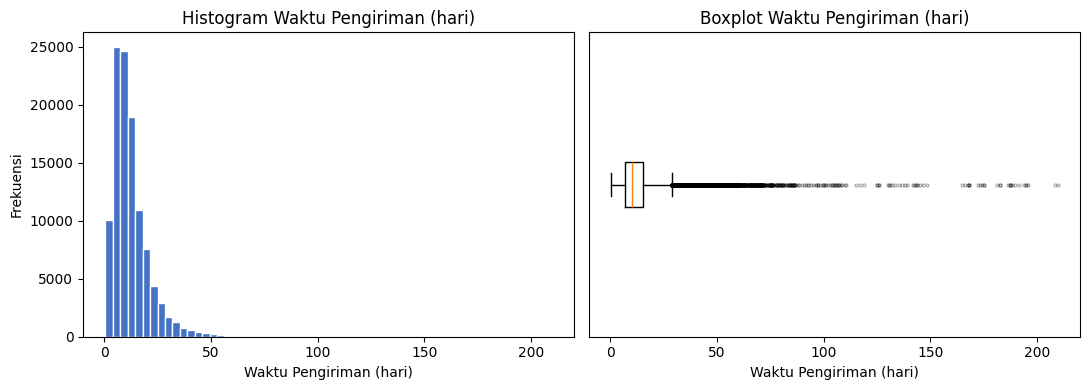

In [ ]:
plot_deskriptif("waktu_pengiriman_hari")

## 5. Penyajian Data: Distribusi Frekuensi Waktu Pengiriman
Batas kelas dibuat manual karena data memiliki ekor yang panjang (nilai maksimum jauh di atas sebagian besar data).

In [ ]:
s = df['waktu_pengiriman_hari'].dropna()

batas = [0, 7, 14, 21, 28, 42, 60, np.inf]
label = ['0-7', '>7-14', '>14-21', '>21-28',
         '>28-42', '>42-60', '>60']

kelas = pd.cut(
    s,
    bins=batas,
    labels=label,
    right=True,
    include_lowest=True
)

frekuensi = kelas.value_counts(sort=False)
frekuensi_kumulatif = frekuensi.cumsum()

tabel = pd.DataFrame({
    'Kelas (hari)': label,
    'Frekuensi': frekuensi.values
})

tabel['Frekuensi relatif (%)'] = (
    tabel['Frekuensi'] / len(s) * 100
).round(2)

tabel['Frekuensi kumulatif'] = frekuensi_kumulatif.values

tabel['Frekuensi kumulatif relatif (%)'] = (
    tabel['Frekuensi kumulatif'] / len(s) * 100
).round(2)

display(tabel)
print('Total data:', len(s))


,Kelas (hari),Frekuensi,Frekuensi relatif (%),Frekuensi kumulatif,Frekuensi kumulatif relatif (%)
0,0-7,30028,27.25,30028,27.25
1,>7-14,46034,41.78,76062,69.03
2,>14-21,20175,18.31,96237,87.34
3,>21-28,7746,7.03,103983,94.37
4,>28-42,4587,4.16,108570,98.53
5,>42-60,1286,1.17,109856,99.70
6,>60,333,0.30,110189,100.00


Total data: 110189


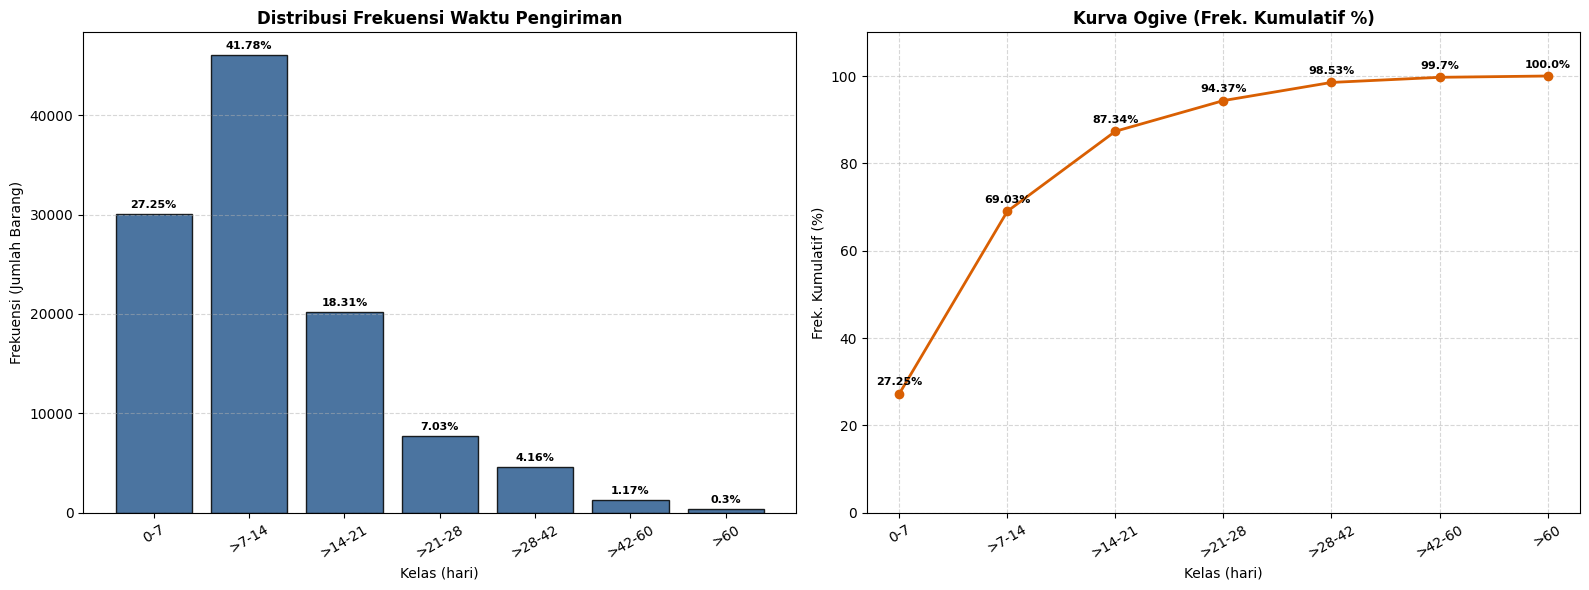

In [ ]:
# 1. Buat folder penyimpan jika belum ada
os.makedirs('hasil_analisis', exist_ok=True)

# 2. Buat Figure & Subplots (2 grafik berdampingan)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- GRAFIK 1: Bar Chart (Frekuensi Waktu Pengiriman) ---
bars = axes[0].bar(
    tabel['Kelas (hari)'],
    tabel['Frekuensi'],
    color='#2b5c8f',
    edgecolor='black',
    alpha=0.85,
)
axes[0].set_title(
    'Distribusi Frekuensi Waktu Pengiriman', fontsize=12, fontweight='bold'
)
axes[0].set_xlabel('Kelas (hari)', fontsize=10)
axes[0].set_ylabel('Frekuensi (Jumlah Barang)', fontsize=10)
axes[0].tick_params(axis='x', rotation=30)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# Menambahkan angka Frekuensi Relatif (%) di atas setiap batang
for bar, rel in zip(bars, tabel['Frekuensi relatif (%)']):
    if bar.get_height() > 0:
        axes[0].annotate(
            f'{rel}%',
            xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
            xytext=(0, 3),
            textcoords='offset points',
            ha='center',
            va='bottom',
            fontsize=8,
            fontweight='bold',
        )

# --- GRAFIK 2: Kurva Ogive (Frekuensi Kumulatif %) ---
axes[1].plot(
    tabel['Kelas (hari)'],
    tabel['Frekuensi kumulatif relatif (%)'],
    marker='o',
    color='#d95f02',
    linewidth=2,
    markersize=6,
)
axes[1].set_title(
    'Kurva Ogive (Frek. Kumulatif %)', fontsize=12, fontweight='bold'
)
axes[1].set_xlabel('Kelas (hari)', fontsize=10)
axes[1].set_ylabel('Frek. Kumulatif (%)', fontsize=10)
axes[1].tick_params(axis='x', rotation=30)
axes[1].set_ylim(0, 110)
axes[1].grid(True, linestyle='--', alpha=0.5)

# Menampilkan titik persentase kumulatif di grafik ogive
for i, val in enumerate(tabel['Frekuensi kumulatif relatif (%)']):
    axes[1].annotate(
        f'{val}%',
        xy=(i, val),
        xytext=(0, 6),
        textcoords='offset points',
        ha='center',
        fontsize=8,
        fontweight='bold',
    )

# 3. Simpan dan Tampilkan Grafik
plt.tight_layout()
plt.savefig('hasil_analisis/distribusi_waktu_pengiriman.png', dpi=300)
plt.show()

## 6. Perbandingan Waktu Pengiriman antar Kelompok Ongkos Kirim
Pesanan dibagi menjadi empat kelompok berdasarkan kuartil ongkos kirim (K1 = terendah, K4 = tertinggi). Pembagian memakai peringkat agar jumlah data tiap kelompok seimbang walaupun banyak nilai ongkir yang sama.

In [ ]:
nama_kel = ["K1 (terendah)", "K2", "K3", "K4 (tertinggi)"]
df["kelompok_ongkir"] = pd.qcut(df["freight_value"].rank(method="first"), 4, labels=nama_kel)

kelompok = df.groupby("kelompok_ongkir", observed=True).agg(
    n=("waktu_pengiriman_hari", "count"),
    ongkir_min=("freight_value", "min"),
    ongkir_max=("freight_value", "max"),
    mean=("waktu_pengiriman_hari", "mean"),
    median=("waktu_pengiriman_hari", "median"),
    std=("waktu_pengiriman_hari", "std"),
).round(2)
kelompok.columns = ["n", "Ongkir Min (BRL)", "Ongkir Max (BRL)",
                    "Mean Waktu (hari)", "Median Waktu (hari)", "Std Dev Waktu"]
kelompok.index.name = "Kelompok Ongkos Kirim"
kelompok

,n,Ongkir Min (BRL),Ongkir Max (BRL),Mean Waktu (hari),Median Waktu (hari),Std Dev Waktu
Kelompok Ongkos Kirim,,,,,,
K1 (terendah),27548,0.00,13.08,7.64,6.18,6.43
K2,27547,13.08,16.26,12.20,10.26,8.15
K3,27547,16.26,21.15,14.07,11.91,9.52
K4 (tertinggi),27547,21.15,409.68,15.97,13.35,10.97


### Gambar 4. Boxplot waktu pengiriman per kelompok ongkos kirim
Nilai ekstrem tidak ditampilkan agar perbedaan kotak (Q1-median-Q3) antar kelompok terlihat jelas.

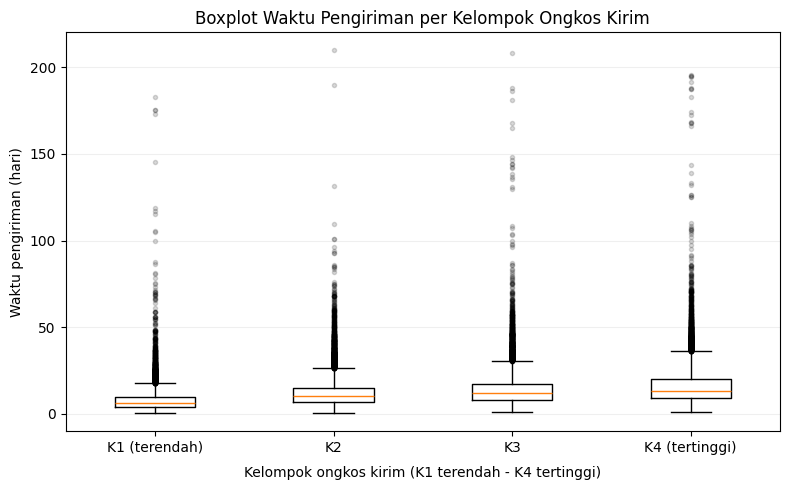

In [ ]:
import os
import matplotlib.pyplot as plt

# 1. Kelompokkan data
grup = [
    df.loc[df["kelompok_ongkir"] == k, "waktu_pengiriman_hari"] for k in nama_kel
]

plt.figure(figsize=(8, 5))

# Kustomisasi tampilan outlier (titik hitam kecil dengan efek transparan)
flierprops = dict(
    marker='o',
    markersize=3,
    markerfacecolor='black',
    markeredgecolor='black',
    alpha=0.15,
)

# 2. Buat Boxplot dengan menampilkan outlier (showfliers=True)
plt.boxplot(grup, showfliers=True, flierprops=flierprops)

# 3. Pengaturan Label, Judul, dan Ticks
plt.xticks(range(1, len(nama_kel) + 1), nama_kel)
plt.xlabel(
    "Kelompok ongkos kirim (K1 terendah - K4 tertinggi)",
    fontsize=10,
    labelpad=8,
)
plt.ylabel("Waktu pengiriman (hari)", fontsize=10)
plt.title("Boxplot Waktu Pengiriman per Kelompok Ongkos Kirim", fontsize=12)

# Grid horizontal tipis seperti di gambar
plt.grid(axis='y', linestyle='-', alpha=0.2)

plt.tight_layout()

# 4. Simpan dan Tampilkan Grafik
os.makedirs("hasil_analisis", exist_ok=True)
plt.savefig("hasil_analisis/boxplot_kelompok_ongkir.png", dpi=300)
plt.show()

## 7. Simpan Hasil

In [ ]:
import shutil
os.makedirs("hasil_analisis", exist_ok=True)

with pd.ExcelWriter("hasil_analisis/hasil_analisis.xlsx") as w:
    deskriptif.to_excel(w, sheet_name="Deskriptif", index=True)
    efek_outlier.to_excel(w, sheet_name="Efek Outlier", index=True)
    tabel_frek.to_excel(w, sheet_name="Distribusi Frekuensi", index=True)
    kelompok.to_excel(w, sheet_name="Kelompok Ongkir", index=True)

# Kompres folder hasil_analisis menjadi hasil_analisis.zip
shutil.make_archive("hasil_analisis", "zip", "hasil_analisis")

# Unduh file zip
files.download("hasil_analisis.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>